# 02 — Qué mide cada variable del hospital

**Datos:** 433.258 triages del 1 de enero de 2020 al 20 de septiembre de 2026, sin la caída de registro
del 21 de marzo de 2024 (cuaderno 01).

## Pregunta y motivo

El cuaderno 01 describió cuánta gente consulta y cuándo. Este cuaderno revisa qué se sabe de cada
consulta y, sobre todo, qué mide cada variable disponible. La razón es práctica: un nivel de triage, una
estancia o el nombre de la aseguradora no son lo mismo que el número de personas enfermas en Manizales, y
usar una variable por otra produce conclusiones falsas. Antes de cruzar el hospital con factores externos
conviene saber qué variables describen a la población, cuáles describen cómo decide y registra el
hospital, y cuáles describen la red de aseguradoras que lo rodea.

Las variables se agrupan en tres familias:

| Familia | Qué mide | Variables |
|---|---|---|
| **Población** | Cuánta gente enferma y de qué | conteo, edad, hora de llegada |
| **Institución** | Qué decide y qué registra el hospital con esa gente | nivel de triage, estancia |
| **Red** | Quién paga la atención y a dónde puede ir el paciente | entidad administradora (EPS, SOAT, ARL) |

El conteo y la edad funcionan como termómetro de Manizales; el nivel y la estancia, como termómetro del
hospital; la entidad, como termómetro de la red. Cada una responde preguntas distintas. El conteo puede
caer sin que enferme menos gente, por ejemplo, si una aseguradora deja de enviar a sus afiliados.

## Supuestos del cuaderno

- El desenlace del proyecto es el conteo total de triages; las demás variables ayudan a entenderlo.
- Todos los registros se tratan como demanda real (sección 3).
- En los subconjuntos (una banda de edad, una aseguradora) un día sin filas es un día con cero consultas;
  en el total, un día sin filas es una caída de registro y se excluye (cuaderno 01).

## Fuentes

Solo se usan agregados, sin datos personales. Ninguna celda de este cuaderno consulta la base clínica.

| Archivo | Qué es | Origen |
|---|---|---|
| `salidas/triage_nivel.parquet` | día × hora × nivel de urgencia | tabla de triage del hospital, nivel de urgencia |
| `salidas/triage_edad.parquet` | día × banda de edad (0-4, 5-14, 15-44, 45-64, 65+) | edad, solo en bandas |
| `salidas/triage_estancia.parquet` | por día: n, media y máximo de la estancia en minutos | hora de salida menos hora de ingreso al turno |
| `salidas/triage_entidad.parquet` | día × hora × entidad administradora | entidad, clasificada por nombre en 14 grupos |
| `salidas/perfil_ingreso_nivel.parquet`, `perfil_ingreso_banda.parquet` | mes × nivel (o banda) × si el triage terminó en ingreso | agregados mensuales; las casillas con menos de 5 casos se ocultan |
| `calendarios/vigilancia_sivigila.csv.gz` | IRA semanal de Manizales (evento 995) | microdatos SIVIGILA, Instituto Nacional de Salud |
| `calendarios/seguridad_mindefensa.csv.gz` | lesiones de tránsito diarias en Manizales | Policía, datos.gov.co |
| `calendarios/clima_unificado.csv.gz` | clima diario de Manizales | IDEAM, METAR La Nubia, Open-Meteo, NASA POWER |

In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ)); warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.patches import Patch

from clustering.visualizaciones import datos
from extraccion.entidades import clasificar

AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
ROJO, VIOLETA = "#c23b22", "#8b5fa8"
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "savefig.facecolor": SUP,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUDO,
    "grid.color": "#e6e5e1", "grid.linewidth": .6, "axes.labelcolor": TINTA2,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlecolor": TINTA, "font.size": 10, "legend.frameon": False})

FIN = "2026-09-20"                         # el 21 y el 22 de septiembre están incompletos
CAIDOS = [pd.Timestamp("2024-03-21")]      # caída del registro (cuaderno 01)
def recorte(t):
    t = t.copy(); t["dia"] = pd.to_datetime(t["dia"])
    return t[(t["dia"] <= FIN) & ~t["dia"].isin(CAIDOS)]

nivel = recorte(pd.read_parquet(RAIZ / "salidas" / "triage_nivel.parquet"))
edad  = recorte(pd.read_parquet(RAIZ / "salidas" / "triage_edad.parquet"))
estancia = recorte(pd.read_parquet(RAIZ / "salidas" / "triage_estancia.parquet")).sort_values("dia")
entidad_completa = clasificar(pd.read_parquet(RAIZ / "salidas" / "triage_entidad.parquet"))
entidad = recorte(entidad_completa)

MES = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
BANDAS = ["0-4", "5-14", "15-44", "45-64", "65-+"]
ROT = {"65-+": "65+"}
print(f"nivel   : {len(nivel):,} filas día x hora x nivel, {nivel['n'].sum():,} triages")
print(f"edad    : {len(edad):,} filas día x banda, {edad['n'].sum():,} triages")
print(f"estancia: {len(estancia):,} días, {estancia['n'].sum():,} triages con estancia "
      f"({100*estancia['n'].sum()/nivel['n'].sum():.1f} % del total)")
print(f"entidad : {entidad['n'].sum():,} triages hasta {FIN} "
      f"(el archivo completo llega a {entidad_completa['dia'].max():%Y-%m-%d} y suma {entidad_completa['n'].sum():,})")

nivel   : 177,720 filas día x hora x nivel, 433,258 triages
edad    : 12,324 filas día x banda, 433,258 triages
estancia: 2,452 días, 394,704 triages con estancia (91.1 % del total)
entidad : 433,258 triages hasta 2026-09-20 (el archivo completo llega a 2026-09-28 y suma 434,726)


---
# 1. Inventario de variables

| Variable | Qué es | Cobertura | Desde | Uso |
|---|---|---|---|---|
| Fecha y hora de triage | Eje temporal | 100 % | 2020 | Sí, es el eje |
| Nivel de triage | Clasificación asignada en la admisión | 100 % | 2020 | Sí, como medida de la decisión del hospital (sección 3) |
| Edad | Años cumplidos, solo en bandas | 100 % | 2020 | Sí (sección 2) |
| Entidad administradora | EPS, aseguradora SOAT, ARL, particular | 100 % en 2020-2024, 99 % en 2025-2026 | 2020 | Sí (sección 5) |
| Estancia | Hora de salida menos hora de ingreso al turno | 91,1 % | 2020 | Solo dentro de un régimen de medición (sección 4) |
| Motivo de consulta | Texto libre del triage | 82,8 % en 2025, 76,2 % en 2026 | 2025 | Existe, pero solo cubre desde 2025 |
| Diagnóstico CIE-10 del triage | Código diagnóstico | 0,6 % | — | No: la columna está vacía |

Las coberturas son las medidas al extraer cada variable. La del diagnóstico merece una explicación.

**La columna de diagnóstico del triage está vacía.** Apunta a un catálogo de 12.427 códigos CIE-10; si
estuviera poblada, habría una clasificación clínica estructurada de cada triage desde 2020. Tiene una
cobertura global de 0,6 % y es nula en 2022, 2025 y 2026. Lo que sí existe es el diagnóstico principal de
quienes ingresan: se obtiene enlazando el triage con el ingreso y con los folios clínicos, y cubre del 98 %
al 99 % de los ingresos. Eso permite series por diagnóstico desde 2020 que no dependen de ningún modelo de
lenguaje, pero solo para la fracción de los triages que termina en ingreso (sección 3).

**La única variable con el motivo clínico de todos los triages es texto libre y solo existe desde 2025.**
Esto crea una asimetría que condiciona el plan: para cuánta gente consulta y de qué edad hay seis años y
medio de historia; para de qué se queja, veinte meses.

---
# 2. Edad

La edad está al 100 % desde 2020 y no depende de ningún modelo. Es la variable de población más
informativa que se tiene sin leer el motivo.

COMPOSICIÓN POR EDAD, 2020-2026 (% de los triages)
banda
0-4       3.1
5-14      4.4
15-44    54.4
45-64    18.5
65+      19.5

CUOTA POR AÑO (%)
banda  0-4  5-14  15-44  45-64   65+
anio                                
2020   1.9   3.0   55.1   19.8  20.2
2021   2.4   3.0   57.9   18.7  17.9
2022   3.2   4.5   56.5   17.9  17.8
2023   2.7   4.2   55.7   18.4  18.9
2024   3.0   4.5   54.0   18.9  19.6
2025   4.0   5.6   51.1   18.4  20.9
2026   4.0   5.1   51.0   18.0  21.8

TRIAGES POR DÍA DE CADA BANDA
banda  0-4  5-14  15-44  45-64   65+
anio                                
2020   2.0   3.2   58.3   20.9  21.4
2021   3.6   4.6   86.5   27.9  26.7
2022   6.1   8.6  107.2   33.9  33.8
2023   5.2   8.2  107.2   35.5  36.3
2024   6.8  10.3  122.1   42.8  44.3
2025   7.9  11.3  101.9   36.6  41.7
2026   6.9   8.9   88.1   31.1  37.6

CAMBIO 2024 -> 2026 EN TRIAGES POR DÍA (%)
banda
0-4       0.0
5-14    -13.0
15-44   -28.0
45-64   -27.0
65+     -15.0


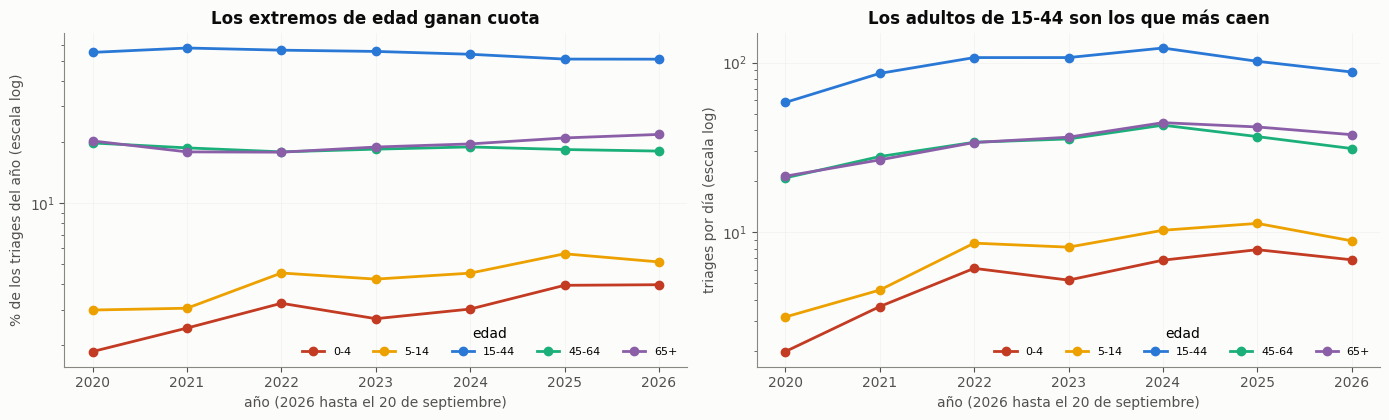

In [2]:
edad["anio"] = edad["dia"].dt.year
total_b = edad.groupby("banda")["n"].sum()
comp = 100 * total_b / total_b.sum()
print("COMPOSICIÓN POR EDAD, 2020-2026 (% de los triages)")
print(comp.reindex(BANDAS).round(1).rename(index=ROT).to_string())

por_anio = edad.pivot_table(index="anio", columns="banda", values="n", aggfunc="sum").fillna(0)[BANDAS]
cuota = 100 * por_anio.div(por_anio.sum(axis=1), axis=0)
dias_anio = edad.groupby("anio")["dia"].nunique()
por_dia = por_anio.div(dias_anio, axis=0)
print("\nCUOTA POR AÑO (%)"); print(cuota.round(1).rename(columns=ROT).to_string())
print("\nTRIAGES POR DÍA DE CADA BANDA"); print(por_dia.round(1).rename(columns=ROT).to_string())
cambio = 100 * (por_dia.loc[2026] / por_dia.loc[2024] - 1)
print("\nCAMBIO 2024 -> 2026 EN TRIAGES POR DÍA (%)"); print(cambio.round(0).rename(index=ROT).to_string())

COL = dict(zip(BANDAS, [ROJO, AMARILLO, AZUL, AQUA, VIOLETA]))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.3))
for b in BANDAS:
    ax1.plot(cuota.index, cuota[b], marker="o", lw=2, color=COL[b], label=ROT.get(b, b))
    ax2.plot(por_dia.index, por_dia[b], marker="o", lw=2, color=COL[b], label=ROT.get(b, b))
ax1.set_yscale("log"); ax1.set_ylabel("% de los triages del año (escala log)")
ax1.set_title("Los extremos de edad ganan cuota")
ax2.set_yscale("log"); ax2.set_ylabel("triages por día (escala log)")
ax2.set_title("Los adultos de 15-44 son los que más caen")
for ax in (ax1, ax2):
    ax.set_xlabel("año (2026 hasta el 20 de septiembre)"); ax.grid(alpha=.4); ax.legend(title="edad", ncol=5, fontsize=8)
plt.tight_layout(); plt.show()

## Lectura

**El 54,4 % de las consultas son de personas de 15 a 44 años**, población en edad laboral; los menores de
15 años son el 7,5 %. Un servicio donde una de cada dos consultas es de alguien que trabaja es coherente
con una demanda ligada a la vida cotidiana de la ciudad más que con un servicio pediátrico o geriátrico.

La cuota de los extremos de edad crece y la del centro disminuye: los de 0-4 años pasan de 2,4 % en 2021 a
4,0 % en 2026, los de 5-14 de 3,0 % a 5,1 %, los de 65 o más de 17,9 % a 21,8 %, y los de 15-44 bajan de
57,9 % a 51,0 %. La figura derecha muestra qué hay detrás, en triages por día: de 2024 a 2026 los de 15-44
años bajan de 122,1 a 88,1 (−28 %) y los de 65 o más de 44,3 a 37,6 (−15 %), mientras los de 0-4 años pasan
de 6,8 a 6,9. **La cuota de los extremos sube porque los adultos caen más, no porque lleguen más niños.**

En esos mismos años cambia la red: Nueva EPS pierde buena parte de su volumen (sección 5). Si los afiliados
que dejaron de venir eran sobre todo adultos, ese solo hecho movería la composición por edad. Los datos
disponibles no cruzan edad con aseguradora, así que este análisis no puede separar ambas explicaciones.

**Límite.** Las bandas son anchas: 15-44 mezcla estudiantes, trabajadores y embarazadas, y el 12,5 %
obstétrico de la sección 3 cae casi entero ahí.

## 2.1 Estacionalidad por edad

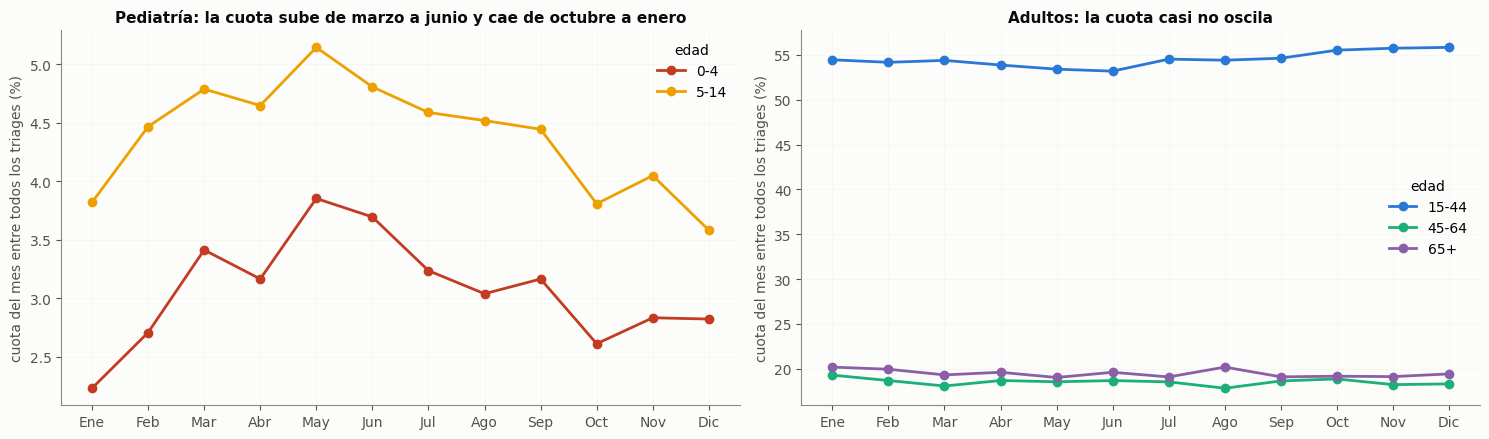

AMPLITUD ESTACIONAL DE LA CUOTA, 2020-2026
      pico valle  amplitud (máx/mín − 1, %)
0-4    May   Ene                       72.7
5-14   May   Dic                       43.6
15-44  Dic   Jun                        5.0
45-64  Ene   Ago                        8.2
65+    Ago   May                        6.1

razón entre la amplitud de 0-4 y la de cada banda adulta: 14.6 (15-44), 8.9 (45-64), 12.0 (65+)

cuota mensual de 0-4 (%): {'Ene': 2.23, 'Feb': 2.71, 'Mar': 3.41, 'Abr': 3.17, 'May': 3.85, 'Jun': 3.7, 'Jul': 3.24, 'Ago': 3.04, 'Sep': 3.17, 'Oct': 2.61, 'Nov': 2.83, 'Dic': 2.82}
razón de 5-14: 8.8 (15-44), 5.3 (45-64), 7.2 (65+)


In [3]:
edad["mes"] = edad["dia"].dt.month
pm = edad.pivot_table(index="mes", columns="banda", values="n", aggfunc="sum").fillna(0)[BANDAS]
cm = 100 * pm.div(pm.sum(axis=1), axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
for b, c in zip(["0-4", "5-14"], [ROJO, AMARILLO]):
    ax1.plot(range(1, 13), cm[b], marker="o", lw=2, label=b, color=c)
ax1.set_title("Pediatría: la cuota sube de marzo a junio y cae de octubre a enero")
for b, c in zip(["15-44", "45-64", "65-+"], [AZUL, AQUA, VIOLETA]):
    ax2.plot(range(1, 13), cm[b], marker="o", lw=2, label=ROT.get(b, b), color=c)
ax2.set_title("Adultos: la cuota casi no oscila")
for ax in (ax1, ax2):
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(MES); ax.legend(title="edad"); ax.grid(alpha=.3)
    ax.set_ylabel("cuota del mes entre todos los triages (%)")
    ax.title.set_fontsize(11)
plt.tight_layout(); plt.show()

amp = pd.DataFrame({"pico": [MES[cm[b].idxmax()-1] for b in BANDAS],
                    "valle": [MES[cm[b].idxmin()-1] for b in BANDAS],
                    "amplitud (máx/mín − 1, %)": [100*(cm[b].max()/cm[b].min()-1) for b in BANDAS]},
                   index=[ROT.get(b, b) for b in BANDAS])
print("AMPLITUD ESTACIONAL DE LA CUOTA, 2020-2026")
print(amp.round(1).to_string())
print(f"\nrazón entre la amplitud de 0-4 y la de cada banda adulta: "
      f"{amp.iloc[0,2]/amp.iloc[2,2]:.1f} (15-44), {amp.iloc[0,2]/amp.iloc[3,2]:.1f} (45-64), {amp.iloc[0,2]/amp.iloc[4,2]:.1f} (65+)")
print("\ncuota mensual de 0-4 (%):", {MES[m-1]: round(v_, 2) for m, v_ in cm["0-4"].items()})
print(f"razón de 5-14: {amp.iloc[1,2]/amp.iloc[2,2]:.1f} (15-44), {amp.iloc[1,2]/amp.iloc[3,2]:.1f} (45-64), {amp.iloc[1,2]/amp.iloc[4,2]:.1f} (65+)")

## Lectura

**Las bandas pediátricas oscilan entre 5 y 15 veces más que las adultas.** La cuota de 0-4 años tiene una
amplitud de 72,7 % (pico en mayo, valle en enero) y la de 5-14 años de 43,6 % (pico en mayo, valle en
diciembre); las adultas están entre 5,0 % y 8,2 %. Las dos curvas pediátricas suben juntas de marzo a junio
y caen juntas de octubre a enero, que es la forma de una temporada respiratoria: los niños son el
indicador temprano de la circulación viral y en Colombia el primer pico de infección respiratoria aguda
se documenta entre marzo y mayo.

Una cuota no es un conteo. La cuota de 0-4 puede subir porque llegan más niños o porque llegan menos
adultos, y un promedio de siete años puede esconder que el pico cambia de mes de un año a otro. La figura
siguiente separa los años y la tabla da los triages por día.

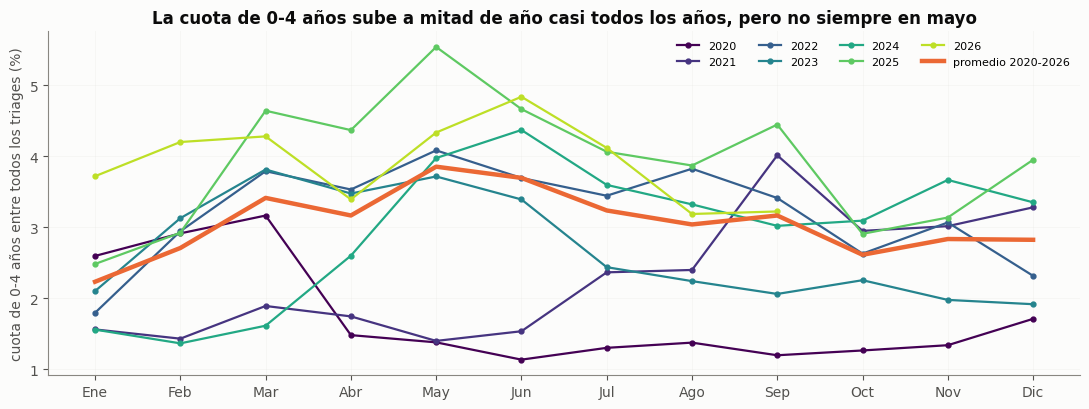

MES DEL PICO DE LA CUOTA 0-4, POR AÑO (2026 solo tiene 9 meses)
{2020: 'Mar', 2021: 'Sep', 2022: 'May', 2023: 'Mar', 2024: 'Jun', 2025: 'May', 2026: 'Jun'}

TRIAGES POR DÍA DE 0-4, MEDIA POR MES Y AÑO
mes   Ene  Feb  Mar  Abr   May   Jun  Jul  Ago  Sep  Oct  Nov  Dic
anio                                                              
2020  4.3  4.6  3.8  1.4   1.9   1.4  1.5  2.0  1.7  2.1  1.9  2.0
2021  2.1  1.8  2.8  2.4   2.2   2.7  3.6  3.7  6.8  5.2  5.9  6.8
2022  3.9  4.7  7.0  6.4   8.7   7.5  7.0  7.3  6.4  4.9  5.8  4.0
2023  4.0  6.2  7.2  6.2   7.4   6.9  5.0  4.6  4.1  4.3  3.8  3.6
2024  3.5  3.0  3.6  6.7   9.9  10.6  8.6  8.0  6.9  6.6  8.0  6.8
2025  5.1  6.0  9.7  8.8  12.0   9.9  8.6  7.8  9.5  6.0  5.4  5.8
2026  5.6  6.2  8.2  6.4   8.3   9.6  6.7  4.7  5.8  NaN  NaN  NaN


In [4]:
x = edad.pivot_table(index=["anio", "mes"], columns="banda", values="n", aggfunc="sum").fillna(0)
cq = 100 * x.div(x.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(11, 4.2))
paleta = plt.get_cmap("viridis")(np.linspace(0, .9, 7))
for col, a in zip(paleta, range(2020, 2027)):
    s = cq.loc[a]["0-4"]
    ax.plot(s.index, s.values, marker="o", ms=3.5, lw=1.6, color=col, label=str(a))
ax.plot(cm.index, cm["0-4"], color=NARANJA, lw=3.2, label="promedio 2020-2026")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(MES); ax.grid(alpha=.3)
ax.set_ylabel("cuota de 0-4 años entre todos los triages (%)")
ax.set_title("La cuota de 0-4 años sube a mitad de año casi todos los años, pero no siempre en mayo")
ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

print("MES DEL PICO DE LA CUOTA 0-4, POR AÑO (2026 solo tiene 9 meses)")
print({a: MES[cq.loc[a]["0-4"].idxmax()-1] for a in range(2020, 2027)})
print("\nTRIAGES POR DÍA DE 0-4, MEDIA POR MES Y AÑO")
d04 = (edad[edad.banda == "0-4"].groupby(["anio", "mes"])["n"].sum() /
       edad[edad.banda == "0-4"].groupby(["anio", "mes"])["dia"].nunique()).unstack()
print(d04.round(1).rename(columns=lambda m: MES[m-1]).to_string())

## Lectura

**En seis de los siete años el pico de 0-4 cae entre marzo y junio** (marzo en 2020 y 2023, mayo en 2022 y
2025, junio en 2024 y 2026). El año que no encaja es 2021, con pico en septiembre; el primer semestre de
2020 está además deformado por el confinamiento por COVID. La temporada de mitad de año se repite, pero su
mes exacto varía; por eso un promedio mensual de siete años la describe bien como forma y mal como fecha.

La tabla de triages por día confirma que el aumento es de conteo y no solo de cuota: en 2022, 2024 y 2025 los
0-4 años pasan de 3,5-5,1 por día en enero a 8,7-12,0 en mayo o junio. En 2020 el conteo se desploma en abril
(1,4 por día, contra 4,6 en febrero) por el confinamiento, y en 2021 crece de forma sostenida hasta fin de año,
así que ninguno de los dos años sigue la forma típica.

**Límite.** La temporada pediátrica coincide con la de lluvias y con el calendario escolar. Están
confundidas, y separarlas exige un diseño que compare años con calendario escolar distinto, no una figura
más.

## 2.2 Contraste con la ciudad: la IRA de 0-4 años en el SIVIGILA

Para saber si la estacionalidad pediátrica del hospital es la de la ciudad, se compara el triage de 0-4
años sumado por semana epidemiológica (domingo a sábado, solo semanas completas) con las consultas por IRA
de 0-4 años de Manizales (evento 995 del SIVIGILA), de 2020 a 2025. Un día sin filas de 0-4 cuenta como
cero.

semanas: 312   r en nivel = 0.703   r normalizando por la media de cada año = 0.808


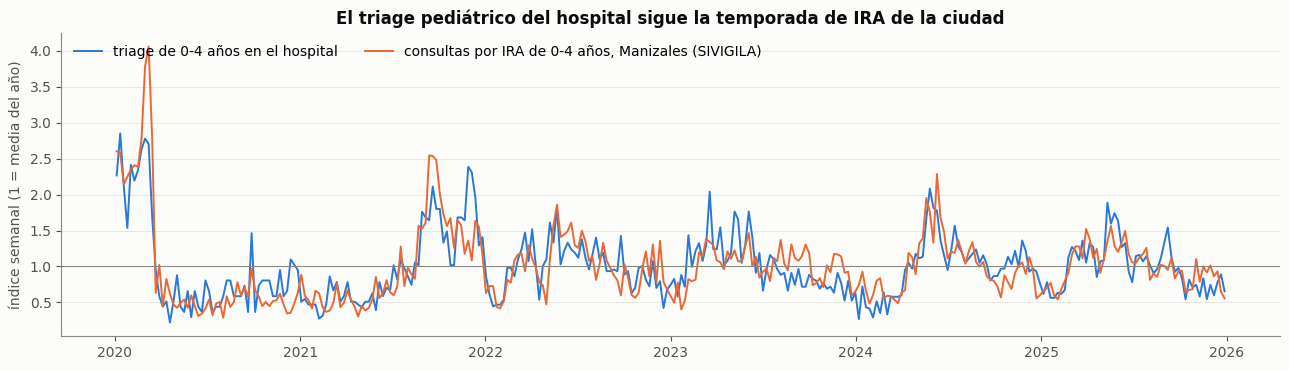

In [5]:
v = pd.read_csv(RAIZ / "calendarios" / "vigilancia_sivigila.csv.gz", parse_dates=["fecha_inicio_semana"])
ira = (v[(v.evento == 995) & (v.ambito == "manizales") & (v.variable == "consultas_ira_0_4")]
         .groupby("fecha_inicio_semana")["valor"].sum())
d04s = (edad[edad.banda == "0-4"].set_index("dia")["n"]
         .reindex(pd.date_range("2020-01-01", FIN)).fillna(0))
d04s[CAIDOS] = np.nan
w = d04s.resample("W-SAT").agg(["sum", "count"]); w.index = w.index - pd.Timedelta(days=6)
w = w[w["count"] == 7]["sum"]
J = pd.concat([w.rename("triage 0-4"), ira.rename("IRA 0-4 Manizales")], axis=1).dropna().loc["2020":"2025"]
r = J.corr().iloc[0, 1]
Jn = J / J.groupby(J.index.year).transform("mean")
print(f"semanas: {len(J)}   r en nivel = {r:.3f}   r normalizando por la media de cada año = {Jn.corr().iloc[0,1]:.3f}")

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(Jn.index, Jn["triage 0-4"], color=AZUL, lw=1.4, label="triage de 0-4 años en el hospital")
ax.plot(Jn.index, Jn["IRA 0-4 Manizales"], color=NARANJA, lw=1.4, label="consultas por IRA de 0-4 años, Manizales (SIVIGILA)")
ax.axhline(1, color=MUDO, lw=.8); ax.set_ylabel("índice semanal (1 = media del año)"); ax.grid(axis="y")
ax.set_title("El triage pediátrico del hospital sigue la temporada de IRA de la ciudad"); ax.legend(loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

## Lectura

**El triage pediátrico del hospital sube y baja con la IRA pediátrica de la ciudad:** r = 0,703 en 312
semanas, y 0,808 al quitar el nivel de cada año, de modo que la coincidencia no es una tendencia compartida
sino la forma de la temporada. La cifra reproduce la de la documentación de la vigilancia. No es una
coincidencia mecánica, porque el hospital casi no reporta IRA al SIVIGILA.

**Límites.** Son dos series con la misma estacionalidad: la correlación indica que la temporada es la misma,
no que una cause la otra. Semana a semana la correlación es mucho menor (0,18 a 0,22 según la
documentación de la vigilancia). Y el cuaderno 07 buscó el efecto de las subidas de la IRA de la ciudad
sobre el triage total y no encontró nada: los 0-4 años son el 3,1 % del total y el efecto se diluye.

## 2.3 El clima como contexto de la temporada pediátrica

Manizales está a unos 2.150 m en la Cordillera Central. La figura siguiente pone la lluvia media de cada
mes junto a la forma de la cuota de 0-4 años, solo para comparar formas: las unidades son distintas y la
cuota se reescala a la media de la lluvia.

días: 2,432 (2020-01-01 a 2026-08-28)
temperatura media 16.6 °C (sd 0.76)   máxima media 21.0 °C
días con máxima > 26 °C: 0   > 25 °C: 4 (0.16 %)
humedad media 86.9 %

lluvia 2020-2025: 1292 mm/año de media  {2020: 1074, 2021: 828, 2022: 1729, 2023: 1390, 2024: 1424, 2025: 1310}
mm/día por mes: {'Ene': 3.11, 'Feb': 2.48, 'Mar': 5.67, 'Abr': 4.26, 'May': 3.8, 'Jun': 5.31, 'Jul': 3.16, 'Ago': 2.58, 'Sep': 1.81, 'Oct': 4.51, 'Nov': 3.07, 'Dic': 2.42}
días con pluviómetro válido: 34.7 %   días con lluvia (>= 1 mm): 64.0 %


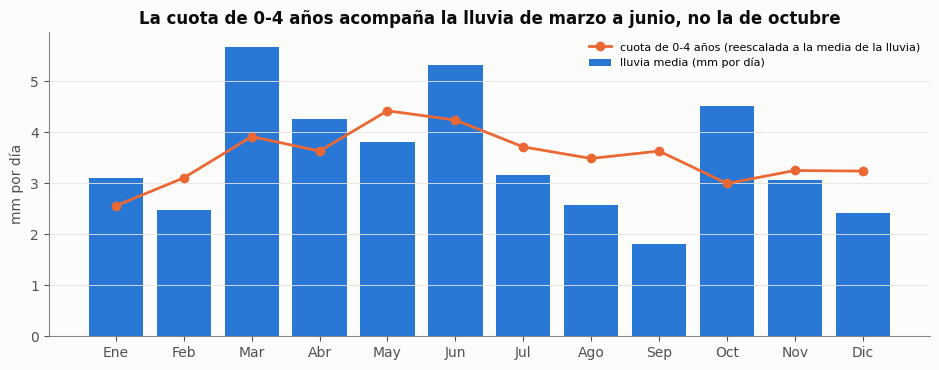

In [6]:
cl = pd.read_csv(RAIZ / "calendarios" / "clima_unificado.csv.gz", parse_dates=["fecha"]).set_index("fecha")
t = cl["temp_media_consenso"]; tx = cl["temp_max_consenso"]
print(f"días: {len(cl):,} ({cl.index.min():%Y-%m-%d} a {cl.index.max():%Y-%m-%d})")
print(f"temperatura media {t.mean():.1f} °C (sd {t.std():.2f})   máxima media {tx.mean():.1f} °C")
print(f"días con máxima > 26 °C: {(tx > 26).sum()}   > 25 °C: {(tx > 25).sum()} ({100*(tx > 25).mean():.2f} %)")
print(f"humedad media {cl['humedad_consenso'].mean():.1f} %")

p = cl["precip_consenso_mm"]
anual = p.loc["2020":"2025"].groupby(p.loc["2020":"2025"].index.year).sum()
print(f"\nlluvia 2020-2025: {anual.mean():.0f} mm/año de media  {anual.round(0).astype(int).to_dict()}")
pm_ = p.groupby(p.index.month).mean()
print("mm/día por mes:", {MES[m-1]: round(v_, 2) for m, v_ in pm_.items()})
print(f"días con pluviómetro válido: {100*cl['precip_con_estacion'].mean():.1f} %   días con lluvia (>= 1 mm): {100*cl['llovio'].mean():.1f} %")

fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.bar(range(1, 13), pm_.values, color=AZUL, label="lluvia media (mm por día)")
c04 = cm["0-4"]
ax.plot(range(1, 13), c04 / c04.mean() * pm_.mean(), color=NARANJA, marker="o", lw=2,
        label="cuota de 0-4 años (reescalada a la media de la lluvia)")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(MES); ax.set_ylabel("mm por día"); ax.grid(axis="y")
ax.set_title("La cuota de 0-4 años acompaña la lluvia de marzo a junio, no la de octubre")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

## Lectura

**Aquí no hace calor.** En 2.432 días la temperatura máxima nunca superó los 26 °C y solo superó los 25 °C
en cuatro. La temperatura media es de 16,6 °C (desviación típica de 0,76) y la humedad media de 86,9 %.
Como el mecanismo de los vectores del dengue y la chikunguña necesita calor sostenido, la transmisión local
queda poco probable. Para el hospital quedan los pacientes remitidos de municipios más bajos de Caldas y las
enfermedades que sí encajan en un clima fresco y húmedo: respiratorias, virales y fúngicas.

La lluvia muestra dos temporadas, marzo-junio (con marzo como mes más lluvioso, 5,67 mm por día) y octubre
(4,51), con el valle claro en septiembre (1,81). **El pico pediátrico de mayo cae dentro de la primera
temporada de lluvias; la segunda no tiene pico pediátrico detrás** (la cuota de 0-4 años de octubre es la segunda
más baja del año, después de la de enero; ver la cuota mensual impresa en la sección 2.1). Si ambos picos coincidieran, la explicación más simple sería una
estacionalidad compartida; que solo coincida uno obliga a buscar qué distingue marzo-junio de octubre, y
ahí entran el calendario escolar, la circulación viral de cada año y la temperatura.

El análisis de mecanismos (cuaderno 07) midió el efecto del paso de seco a lluvioso sobre los 0-4 años:
**+13,4 ± 15,0 % a los 7-13 días y +10,0 ± 16,4 % a los 14-20 días**, con 17 episodios. Conserva la forma
que predice el mecanismo, con subida en la primera y segunda semana, pero no se distingue de cero.

**Límites.** La serie de lluvia usa el pluviómetro como referencia y rellena con una estimación satelital
escalada; solo el 34,7 % de los días tiene pluviómetro válido, de modo que para una climatología mensual
alcanza y para transiciones día a día no. La lluvia anual (unos 1.290 mm) queda por debajo de los cerca de
2.000 mm del municipio: no se sabe resolver, y no afecta a lo que se mide como anomalía del propio mes.

---
# 3. El nivel de triage mide la decisión del hospital

El nivel está al 100 % desde 2020, pero no mide lo que su nombre sugiere. La figura compara, para cada
nivel, su peso entre los triages y la fracción de esos triages que terminó en ingreso al hospital.

nivel                          triages   cuota  % con ingreso
IIIU urgencia                  106,550   24.6%          93.1%
IV no urgente                  169,651   39.2%          14.0%
V consulta externa              52,986   12.2%           0.0%
III-G obstétrica diferida       47,285   10.9%          64.4%
III diferida                    41,693    9.6%          29.7%
II urgencia médica               6,477    1.5%          94.7%
II-G urgencia obstétrica         6,296    1.5%          66.6%
I emergencia                     1,460    0.3%          92.5%

IV + V: 51.4 %   emergencias (I e I-G): 1,591 casos (0.37 %)   niveles con sufijo G (obstétricos): 12.5 %
triages de nivel V que terminaron en ingreso: 10 de 52,995


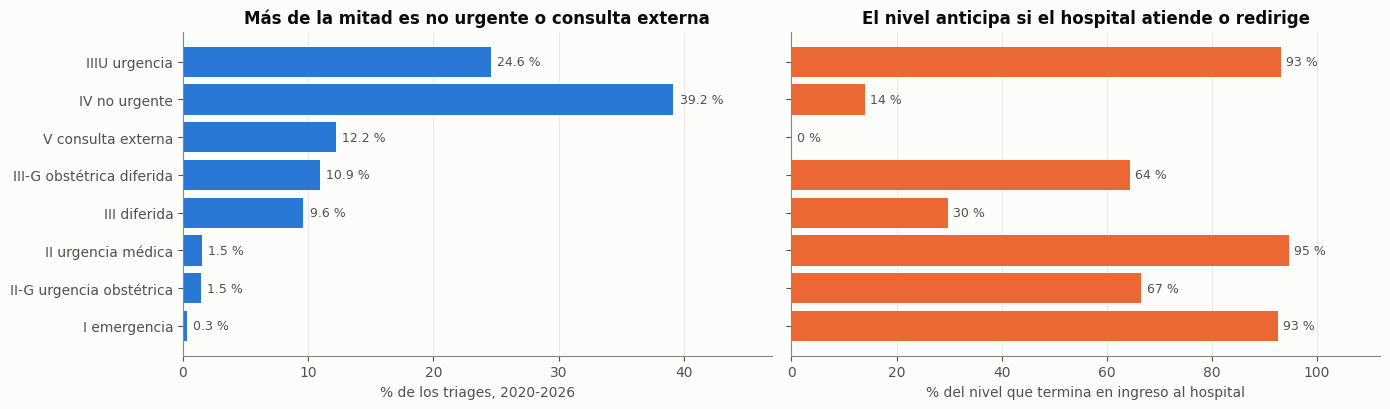


% DE LOS TRIAGES QUE TERMINA EN INGRESO, POR EDAD
banda
0-4      13.3
5-14     15.4
15-44    39.0
45-64    42.6
65+      55.3

% QUE TERMINA EN INGRESO, POR AÑO
anio
2020    51.6
2021    44.5
2022    46.9
2023    49.5
2024    35.2
2025    30.0
2026    34.3

casillas ocultas por tener menos de 5 casos: 490


In [7]:
NIV = {"IIIU": "IIIU urgencia", "IV": "IV no urgente", "V": "V consulta externa", "III-G": "III-G obstétrica diferida",
       "III": "III diferida", "II": "II urgencia médica", "II-G": "II-G urgencia obstétrica", "I": "I emergencia"}
res = nivel.groupby("nivel")["n"].sum()
tot_n = res.sum()
cuota_n = (100 * res / tot_n).reindex(NIV).rename(index=NIV)

ing = pd.read_parquet(RAIZ / "salidas" / "perfil_ingreso_nivel.parquet").dropna(subset=["n"])
a = ing.groupby(["nivel", "con_ingreso"])["n"].sum().unstack().fillna(0)
pct_ing = (100 * a[1] / (a[0] + a[1])).reindex(NIV).rename(index=NIV)

print(f"{'nivel':<28}{'triages':>10}{'cuota':>8}{'% con ingreso':>15}")
for cod, k in NIV.items():
    print(f"{k:<28}{res[cod]:>10,}{cuota_n[k]:>7.1f}%{pct_ing[k]:>14.1f}%")
iv_v = 100 * res[["IV", "V"]].sum() / tot_n
emerg = res[["I", "I-G"]].sum()
obst = 100 * res[res.index.str.contains("G")].sum() / tot_n
print(f"\nIV + V: {iv_v:.1f} %   emergencias (I e I-G): {emerg:,} casos ({100*emerg/tot_n:.2f} %)   niveles con sufijo G (obstétricos): {obst:.1f} %")
print(f"triages de nivel V que terminaron en ingreso: {int(a.loc['V', 1])} de {int(a.loc['V'].sum()):,}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
y = np.arange(len(cuota_n))[::-1]
ax1.barh(y, cuota_n.values, color=AZUL)
for yy, v_ in zip(y, cuota_n.values):
    ax1.text(v_ + .5, yy, f"{v_:.1f} %", va="center", fontsize=9, color=TINTA2)
ax1.set_yticks(y); ax1.set_yticklabels(cuota_n.index); ax1.set_xlim(0, 47)
ax1.set_xlabel("% de los triages, 2020-2026"); ax1.set_title("Más de la mitad es no urgente o consulta externa")
ax2.barh(y, pct_ing.values, color=NARANJA)
for yy, v_ in zip(y, pct_ing.values):
    ax2.text(v_ + 1, yy, f"{v_:.0f} %", va="center", fontsize=9, color=TINTA2)
ax2.set_xlim(0, 112); ax2.set_xlabel("% del nivel que termina en ingreso al hospital")
ax2.set_title("El nivel anticipa si el hospital atiende o redirige")
for ax in (ax1, ax2): ax.grid(axis="x"); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

ib = pd.read_parquet(RAIZ / "salidas" / "perfil_ingreso_banda.parquet").dropna(subset=["n"])
b = ib[ib.banda != "sin edad"].groupby(["banda", "con_ingreso"])["n"].sum().unstack().fillna(0)
print("\n% DE LOS TRIAGES QUE TERMINA EN INGRESO, POR EDAD")
print((100 * b[1] / (b[0] + b[1])).reindex(BANDAS).round(1).rename(index=ROT).to_string())
ing["anio"] = pd.to_datetime(ing["mes"]).dt.year
ya = ing.groupby(["anio", "con_ingreso"])["n"].sum().unstack()
print("\n% QUE TERMINA EN INGRESO, POR AÑO")
print((100 * ya[1] / (ya[0] + ya[1])).round(1).to_string())
print(f"\ncasillas ocultas por tener menos de 5 casos: {int(pd.read_parquet(RAIZ / 'salidas' / 'perfil_ingreso_nivel.parquet')['suprimido'].sum())}")

## Lectura

**El nivel de triage no califica la legitimidad de la consulta: califica lo que el hospital va a hacer con
ella.** Más de la mitad de los triages (51,4 %) son «no urgente» o «consulta externa» y las emergencias son
el 0,4 % (1.591 casos en casi siete años). La lectura inmediata sería que el hospital recibe consultas que
no lo ameritan, y esa lectura es incorrecta. Un hospital de alta complejidad no tiene capacidad de recibir
y tratar a cualquier persona que llegue, de modo que a quien consulta con un dolor intenso pero sin riesgo
vital se le asigna un nivel bajo, se le resuelve o se le remite a su aseguradora con una cita prioritaria,
y se pasa al siguiente. Un «no urgente» es una persona con un síntoma real a quien se resolvió por otra
vía.

La figura derecha lo respalda con datos: el 93 % de los «IIIU» y el 95 % de los «II» terminan en ingreso,
mientras solo el 14 % de los «IV» y el 0,02 % de los «V» (10 de unos 53.000). Por edad, termina en ingreso
el 55 % de los triages de 65 o más y el 13 % de los de 0-4: se atiende sobre todo a los mayores y se
estabiliza y remite a los niños. Por año, la fracción que ingresa era cercana a la mitad hasta 2023 y pasa a
35,2 % en 2024, 30,0 % en 2025 y 34,3 % en 2026. Hay además un 12,5 % obstétrico (niveles con sufijo G),
una población que no responde al clima como el resto.

Tres consecuencias:

1. **Todos los registros se tratan como demanda real.** No hay forma de separar quién exageró un síntoma, ni
   hace falta: el conteo mide que alguien sintió la necesidad de consultar, que es lo que el proyecto quiere
   anticipar.
2. **El nivel es una variable de la institución, no de la población.** Depende del criterio del personal y
   de la capacidad del servicio en ese momento; sirve para caracterizar al hospital, no para medir la
   gravedad de lo que ocurre en la ciudad.
3. **El umbral puede moverse con la presión del servicio.** Un nivel que se endurece podría ser un
   indicador de saturación; esta hipótesis no se contrasta aquí.

**Límite.** El porcentaje con ingreso usa agregados mensuales en los que las casillas con menos de 5 casos
están ocultas; los niveles raros (I-G, IV-G, V-G) quedan menos precisos.

## 3.1 La deriva del criterio de triage

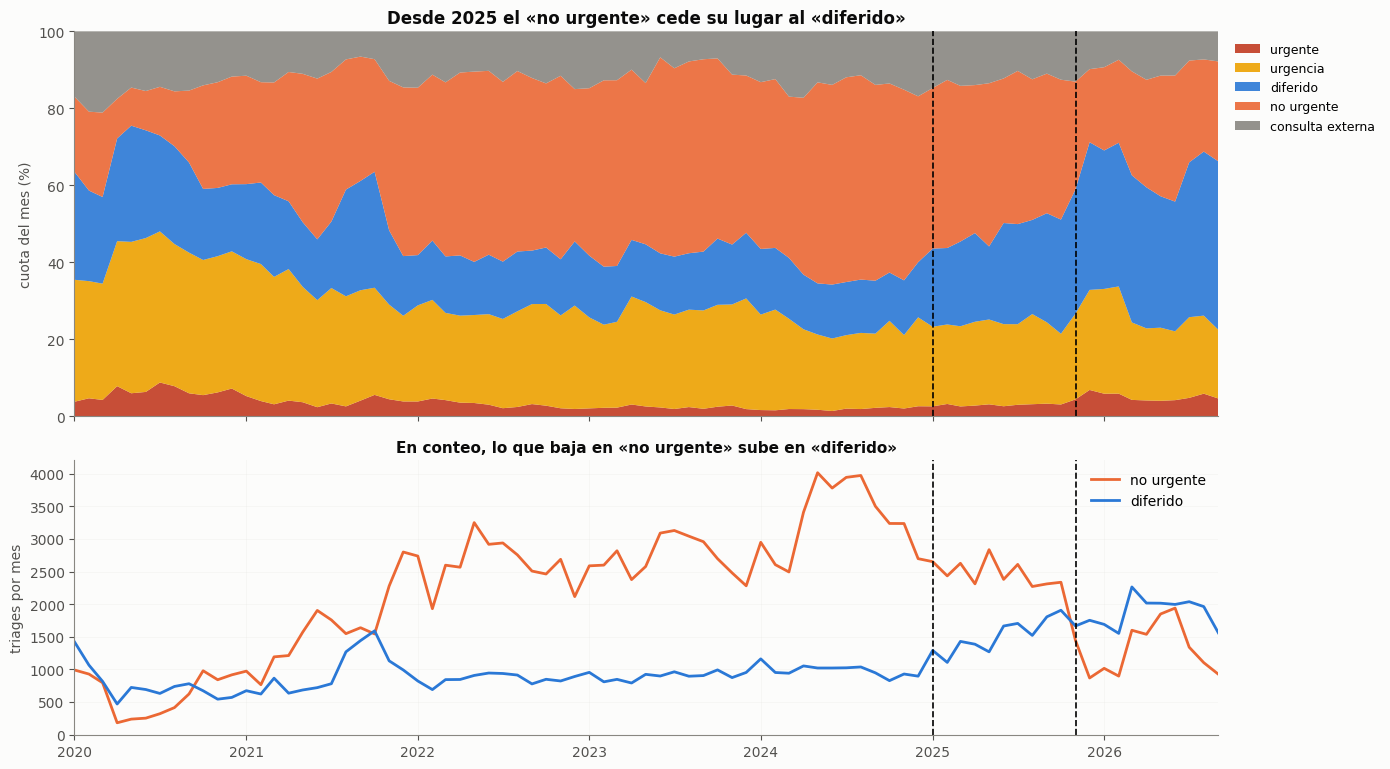

CUOTA POR AÑO (%)
grupo  urgente  urgencia  diferido  no urgente  consulta externa
anio                                                            
2020       5.9      34.9      23.6        19.4              16.2
2021       3.9      29.0      20.9        35.2              10.9
2022       3.1      24.4      14.8        45.5              12.2
2023       2.3      25.4      15.4        46.5              10.4
2024       1.9      21.2      14.3        48.4              14.1
2025       3.3      21.5      25.4        37.2              12.6
2026       4.8      20.9      37.7        26.9               9.7

TRIAGES POR DÍA
grupo  urgente  urgencia  diferido  no urgente  consulta externa
anio                                                            
2020       6.2      36.8      24.9        20.4              17.1
2021       5.8      43.3      31.2        52.6              16.2
2022       5.9      46.2      28.1        86.2              23.1
2023       4.5      48.8      29.6        89.4         

In [8]:
GRUPO = {"I": "urgente", "II": "urgente", "I-G": "urgente", "II-G": "urgente",
         "IIIU": "urgencia", "III": "diferido", "III-G": "diferido",
         "IV": "no urgente", "IV-G": "no urgente",
         "V": "consulta externa", "V-G": "consulta externa"}
nivel["grupo"] = nivel["nivel"].map(GRUPO).fillna("otro")
orden_g = ["urgente", "urgencia", "diferido", "no urgente", "consulta externa"]
COLG = [ROJO, AMARILLO, AZUL, NARANJA, MUDO]

mens = nivel.assign(ym=nivel["dia"].dt.to_period("M")).pivot_table(
    index="ym", columns="grupo", values="n", aggfunc="sum").fillna(0)[orden_g]
x = mens.index.to_timestamp()
cuota_m = 100 * mens.div(mens.sum(axis=1), axis=0)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7.8), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})
ax1.stackplot(x, cuota_m.to_numpy().T, labels=cuota_m.columns, colors=COLG, alpha=.9)
ax1.set_ylim(0, 100); ax1.set_ylabel("cuota del mes (%)")
ax1.set_title("Desde 2025 el «no urgente» cede su lugar al «diferido»")
ax1.legend(loc="upper left", bbox_to_anchor=(1.005, 1), fontsize=9)
for c, col in zip(["no urgente", "diferido"], [NARANJA, AZUL]):
    ax2.plot(x, mens[c], lw=2, label=c, color=col)
ax2.set_ylabel("triages por mes"); ax2.legend(); ax2.grid(alpha=.3)
ax2.set_title("En conteo, lo que baja en «no urgente» sube en «diferido»", fontsize=11)
for ax in (ax1, ax2):
    ax.axvline(pd.Timestamp("2025-01-01"), color="black", lw=1.2, ls="--")
    ax.axvline(pd.Timestamp("2025-11-01"), color="black", lw=1.2, ls="--")
ax1.set_xlim(x.min(), x.max())
plt.tight_layout(); plt.show()

nivel["anio"] = nivel["dia"].dt.year
pa = nivel.pivot_table(index="anio", columns="grupo", values="n", aggfunc="sum")[orden_g]
cu = 100 * pa.div(pa.sum(axis=1), axis=0)
pdia = pa.div(nivel.groupby("anio")["dia"].nunique(), axis=0)
print("CUOTA POR AÑO (%)"); print(cu.round(1).to_string())
print("\nTRIAGES POR DÍA"); print(pdia.round(1).to_string())
print("\nCAMBIO 2024 -> 2026 EN TRIAGES POR DÍA (%)"); print((100 * (pdia.loc[2026] / pdia.loc[2024] - 1)).round(0).to_string())
print("\nTRIAGES POR MES, sep-dic 2025:", {str(k): int(v_) for k, v_ in mens.sum(axis=1).loc["2025-09":"2025-12"].items()})

## Lectura

**El panel inferior muestra que cambió el criterio y no solo quién llega.** «No urgente» cae y «diferido»
sube, en conteo y casi en espejo. La cuota de «no urgente» pasa de 48,4 % en 2024 a 26,9 % en 2026, y la de
«diferido» de 14,3 % a 37,7 %. Si solo se hubieran desviado a otro sitio los casos de menor complejidad,
«diferido» no podría crecer en términos absolutos, y crece: de 2024 a 2026, en triages por día, «diferido»
sube 100 % (de 32,5 a 65,0), «urgente» 88 % y «no urgente» baja 58 % (de 109,8 a 46,4), mientras el total cae. La deriva arranca en enero de 2025 y se acelera en noviembre y diciembre de ese año. Las
emergencias reales no se duplican en dos años: cambió dónde se pone la raya.

La segunda explicación, que cambió quién llega, también tiene parte. En noviembre de 2025 el volumen cae de
golpe (triages por mes de septiembre a diciembre de 2025 en la última línea de la salida) y es el mes en
que Nueva EPS se desploma en el hospital (sección 5). La figura siguiente compara las dos cuotas.

correlación mensual, cuota de «no urgente» contra cuota de Nueva EPS, 2024-01 a 2025-10: r = -0.80  (22 meses)
correlación mensual, cuota de «no urgente» contra cuota de Nueva EPS, 2025-01 a 2025-10: r = -0.60  (10 meses)
correlación mensual, cuota de «no urgente» contra cuota de Nueva EPS, 2025-11 a 2026-09: r = +0.63  (11 meses)


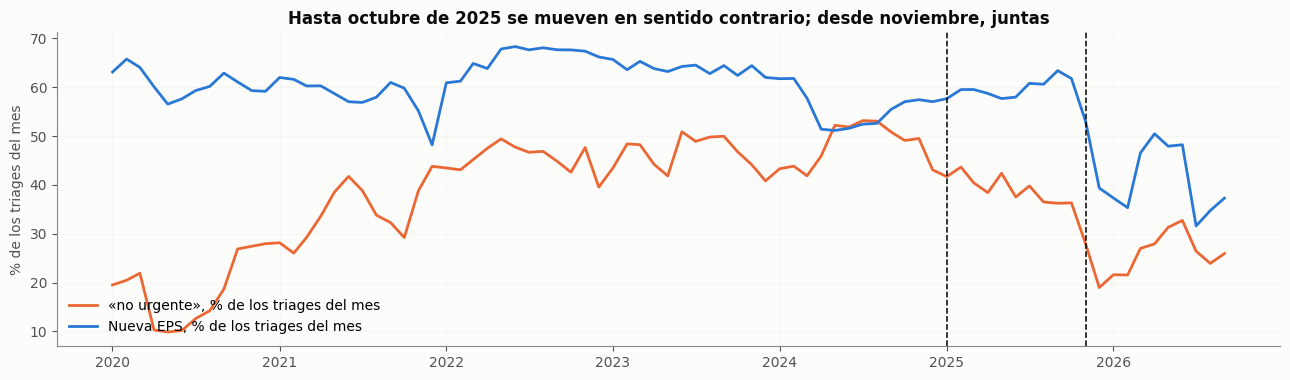

In [9]:
e_m = entidad.assign(ym=entidad["dia"].dt.to_period("M")).pivot_table(
    index="ym", columns="grupo", values="n", aggfunc="sum").fillna(0)
cuota_ne = 100 * e_m.div(e_m.sum(axis=1), axis=0)["nueva_eps"]
nu = cuota_m["no urgente"]
VENT = [("2024-01", "2025-10"), ("2025-01", "2025-10"), ("2025-11", "2026-09")]
for a_, b_ in VENT:
    s1, s2 = nu.loc[a_:b_], cuota_ne.loc[a_:b_]
    print(f"correlación mensual, cuota de «no urgente» contra cuota de Nueva EPS, {a_} a {b_}: r = {s1.corr(s2):+.2f}  ({len(s1)} meses)")

fig, ax = plt.subplots(figsize=(13, 3.9))
xm = nu.index.to_timestamp()
ax.plot(xm, nu.values, color=NARANJA, lw=2, label="«no urgente», % de los triages del mes")
ax.plot(xm, cuota_ne.loc[nu.index].values, color=AZUL, lw=2, label="Nueva EPS, % de los triages del mes")
ax.axvline(pd.Timestamp("2025-01-01"), color="black", lw=1.1, ls="--")
ax.axvline(pd.Timestamp("2025-11-01"), color="black", lw=1.1, ls="--")
ax.set_ylabel("% de los triages del mes"); ax.grid(alpha=.3); ax.legend(loc="lower left")
ax.set_title("Hasta octubre de 2025 se mueven en sentido contrario; desde noviembre, juntas")
plt.tight_layout(); plt.show()

## Lectura

**De enero de 2024 a octubre de 2025 la cuota de «no urgente» y la de Nueva EPS se mueven en sentido
contrario (r = −0,80 en 22 meses); desde noviembre de 2025 se mueven juntas (r = +0,63 en 11 meses).** Con
solo 2025 el primer tramo da r = −0,60 en 10 meses. Así, de enero a octubre de 2025 la caída del «no
urgente» ocurre sin que baje la cuota de Nueva EPS: ese tramo es cambio de criterio. Desde noviembre de
2025 coinciden el desplome de Nueva EPS y una parte del cambio de composición por nivel, y no es posible
distinguir cuánto es criterio y cuánto es quién llega. Las dos cosas son reales y distintas, y ninguna
cambia el conteo salvo por la gente que dejó de venir: cambiar la etiqueta no cambia cuántos consultan.

**Consecuencia para el análisis: un «triage IV» de 2024 y uno de 2026 no son la misma cosa.** El nivel
sirve dentro de un periodo, no entre periodos. Para comparar años hay que usar el conteo total y la edad,
con la aseguradora delante.

**Límites.** Con 11 meses una correlación es frágil. Y sin un cruce nivel × aseguradora no se sabe qué
nivel tenían los afiliados de Nueva EPS que dejaron de venir.

---
# 4. La estancia y sus tres regímenes de medición

La estancia es la diferencia entre la hora de salida y la hora de ingreso al turno. Tiene cobertura de
91,1 % y es estable en todos los años (entre 85 % y 94 %), a diferencia del texto del motivo. El valor,
sin embargo, tiene dos saltos bruscos.

primer día con media móvil de 7 días bajo 20 min después del 1-may-2026: 2026-06-21
media diaria del 20 al 31 de julio de 2021 (min): [5, 11, 11, 13, 9, 8, 19, 88, 42, 56, 54, 50]

régimen  periodo              media (min)   registros
1        2020-01 a 2021-07           10.7      58,211
2        2021-08 a 2026-06           56.0     324,035
3        2026-07 a 2026-09            9.6      12,458

media mensual (min), jun a ago de 2021: {Period('2021-06', 'M'): 11.6, Period('2021-07', 'M'): 18.2, Period('2021-08', 'M'): 64.4}
media mensual (min), may a sep de 2026: {Period('2026-05', 'M'): 45.8, Period('2026-06', 'M'): 30.4, Period('2026-07', 'M'): 9.3, Period('2026-08', 'M'): 9.3, Period('2026-09', 'M'): 10.6}


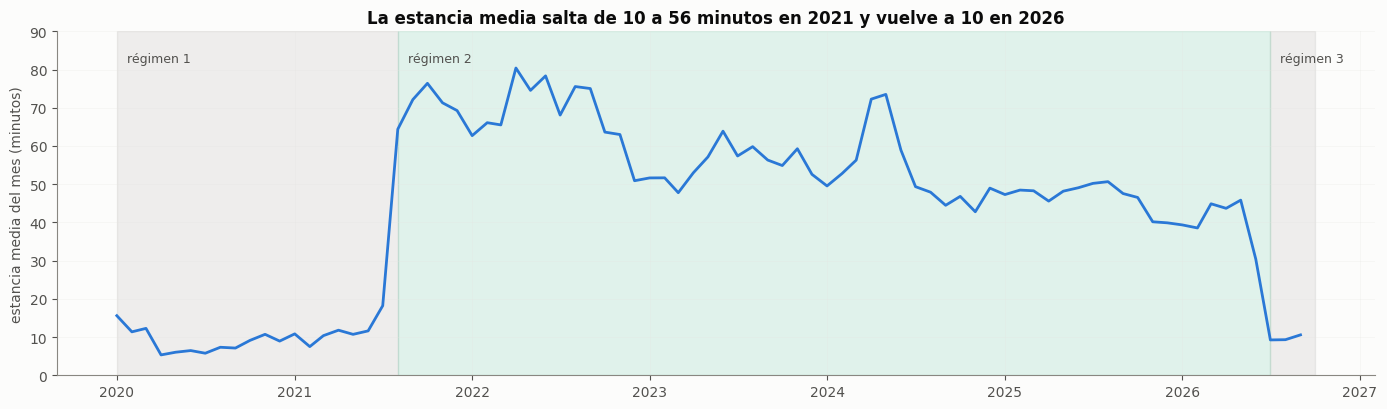

In [10]:
est = estancia.set_index("dia").sort_index()
est["w"] = est["media_min"] * est["n"]
mes_e = est.groupby(est.index.to_period("M"))[["w", "n"]].sum()
mes_e["media"] = mes_e["w"] / mes_e["n"]

r7 = est["media_min"].rolling(7).mean()
sub = r7.loc["2026-05-01":]
print(f"primer día con media móvil de 7 días bajo 20 min después del 1-may-2026: {sub[sub < 20].index.min():%Y-%m-%d}")
print("media diaria del 20 al 31 de julio de 2021 (min):", est.loc["2021-07-20":"2021-07-31", "media_min"].round(0).astype(int).tolist())

REG = [("1", "2020-01", "2021-07"), ("2", "2021-08", "2026-06"), ("3", "2026-07", "2026-09")]
print(f"\n{'régimen':<9}{'periodo':<20}{'media (min)':>12}{'registros':>12}")
for k, a_, b_ in REG:
    s = est.loc[a_:b_]
    print(f"{k:<9}{a_ + ' a ' + b_:<20}{s['w'].sum() / s['n'].sum():>12.1f}{int(s['n'].sum()):>12,}")
print("\nmedia mensual (min), jun a ago de 2021:", mes_e["media"].loc["2021-06":"2021-08"].round(1).to_dict())
print("media mensual (min), may a sep de 2026:", mes_e["media"].loc["2026-05":"2026-09"].round(1).to_dict())

fig, ax = plt.subplots(figsize=(14, 4.2))
xm = mes_e.index.to_timestamp()
ax.plot(xm, mes_e["media"], color=AZUL, lw=2)
for (k, a_, b_), col in zip(REG, [MUDO, AQUA, MUDO]):
    ax.axvspan(pd.Period(a_).start_time, pd.Period(b_).end_time, color=col, alpha=.12)
    ax.text(pd.Period(a_).start_time + pd.Timedelta(days=20), 82, f"régimen {k}", fontsize=9, color=TINTA2)
ax.set_ylim(0, 90); ax.set_ylabel("estancia media del mes (minutos)"); ax.grid(alpha=.3)
ax.set_title("La estancia media salta de 10 a 56 minutos en 2021 y vuelve a 10 en 2026")
plt.tight_layout(); plt.show()

## Lectura

**La estancia no mide un tiempo clínico estable: cambia lo que se graba en la columna de salida.** La media
mensual pasa de unos 10 minutos (régimen 1, enero de 2020 a julio de 2021) a unos 56 (régimen 2, agosto de
2021 a junio de 2026) y regresa a unos 10 (régimen 3, desde julio de 2026). El primer salto ocurre el 27 de julio
de 2021 (la media diaria pasa de 19 a 88 minutos de un día al siguiente); el segundo se completa a lo largo
de junio de 2026, y la media móvil de 7 días baja de 20 minutos desde el 21 de ese mes. Por eso junio de
2026 es un mes de transición (media mensual de 30,4 minutos) y arrastra días del régimen nuevo dentro del
régimen 2. Un servicio de urgencias no cambia su
tiempo de atención por un factor de cinco de un mes a otro: lo que cambió fue el criterio de registro.

La variable se usa solo dentro del régimen 2, de agosto de 2021 a junio de 2026, casi cinco años y unos
324.000 registros. De aquí sale un método general: antes de usar cualquier columna hay que mirar su serie
mensual buscando escalones, porque un cambio de registro no documentado se confunde con un cambio del
fenómeno.

**Límite.** Los datos disponibles son la media y el máximo por día, sin la mediana ni la distribución, y las
fechas de los saltos se leen de esas medias diarias y no de los registros.

---
# 5. La red: la entidad administradora

La tabla de triage incluye la entidad que paga la atención. Las cerca de 330 entidades se agrupan por
nombre en 14 grupos. Es la tercera familia de variables, y trae dos huellas de mecanismo sin leer el
motivo: el SOAT, seguro obligatorio de accidentes de tránsito, y la ARL, el de accidentes laborales.

REPARTO DE LOS TRIAGES POR ENTIDAD (434,726 en el archivo, 2020-01-01 a 2026-09-28)
                          todo el archivo (%)  hasta 2026-09-20 (%)
grupo                                                              
Nueva EPS                                58.2                  58.3
EPS Sura                                 22.2                  22.2
Otras EPS                                 6.1                   6.1
SOAT (tránsito)                           4.0                   4.0
Régimen especial                          2.5                   2.5
Prepagada                                 1.8                   1.8
Particulares                              1.3                   1.3
Ente territorial                          1.3                   1.3
ARL (laboral)                             1.0                   1.0
IPS remitente                             0.6                   0.6
Sin entidad                               0.3                   0.3
ADRES / FOSYGA                  


TRIAGES POR DÍA, MEDIA DEL AÑO
      Nueva EPS  EPS Sura  Otras EPS  SOAT (tránsito)  ARL (laboral)  Particulares
dia                                                                               
2020       64.8       8.6       11.6              5.6            1.6           3.0
2021       86.1      16.8       19.7              7.8            1.9           4.7
2022      125.3      28.5       12.8              8.1            1.8           2.2
2023      122.9      41.1        8.8              7.0            1.7           1.4
2024      125.6      69.6        7.6              7.8            2.0           1.8
2025      115.8      53.9        6.6              6.0            1.7           1.3
2026       72.2      62.0        8.0              7.7            2.3           1.2



sin entidad por año (%): {2020: 0.0, 2021: 0.0, 2022: 0.0, 2023: 0.0, 2024: 0.0, 2025: 0.99, 2026: 1.16}


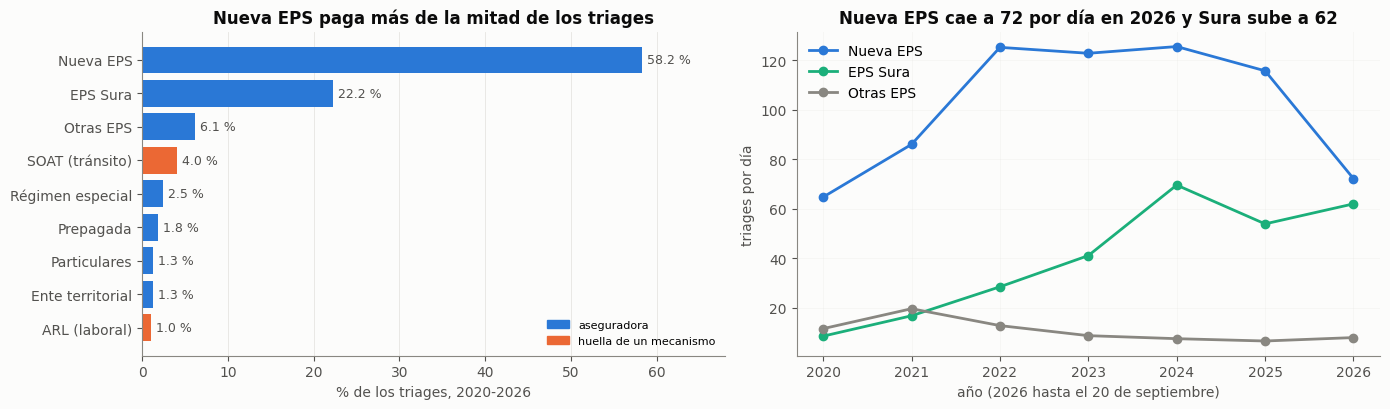

In [11]:
NOMBRE = {"nueva_eps": "Nueva EPS", "sura_eps": "EPS Sura", "otra_eps": "Otras EPS",
          "soat_aseguradora": "SOAT (tránsito)", "regimen_especial": "Régimen especial",
          "prepagada": "Prepagada", "particular": "Particulares", "arl": "ARL (laboral)",
          "ente_territorial": "Ente territorial", "ips_remitente": "IPS remitente",
          "sin_entidad": "Sin entidad", "adres_fosyga": "ADRES / FOSYGA", "otro": "Otro",
          "nueva_eps_complementario": "Nueva EPS complementario"}
rep = pd.DataFrame({
    "todo el archivo (%)": 100 * entidad_completa.groupby("grupo")["n"].sum() / entidad_completa["n"].sum(),
    f"hasta {FIN} (%)": 100 * entidad.groupby("grupo")["n"].sum() / entidad["n"].sum()}
).sort_values("todo el archivo (%)", ascending=False)
rep.index = rep.index.map(NOMBRE)
print(f"REPARTO DE LOS TRIAGES POR ENTIDAD ({entidad_completa['n'].sum():,} en el archivo, "
      f"{entidad_completa['dia'].min():%Y-%m-%d} a {entidad_completa['dia'].max():%Y-%m-%d})")
print(rep.round(1).to_string())

g = entidad.pivot_table(index="dia", columns="grupo", values="n", aggfunc="sum").fillna(0)
por_dia_e = g.groupby(g.index.year).mean()[["nueva_eps", "sura_eps", "otra_eps", "soat_aseguradora", "arl", "particular"]]
por_dia_e.columns = [NOMBRE[c] for c in por_dia_e.columns]
print("\nTRIAGES POR DÍA, MEDIA DEL AÑO"); print(por_dia_e.round(1).to_string())
sin = entidad.assign(anio=entidad["dia"].dt.year, s=np.where(entidad["grupo"] == "sin_entidad", entidad["n"], 0)).groupby("anio")[["s", "n"]].sum()
print("\nsin entidad por año (%):", (100 * sin["s"] / sin["n"]).round(2).to_dict())

top = rep["todo el archivo (%)"].iloc[:9][::-1]
huella = ["SOAT (tránsito)", "ARL (laboral)"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
ax1.barh(top.index, top.values, color=[NARANJA if k in huella else AZUL for k in top.index])
for yy, v_ in enumerate(top.values):
    ax1.text(v_ + .6, yy, f"{v_:.1f} %", va="center", fontsize=9, color=TINTA2)
ax1.set_xlabel("% de los triages, 2020-2026"); ax1.set_xlim(0, 68); ax1.grid(axis="x"); ax1.set_axisbelow(True)
ax1.set_title("Nueva EPS paga más de la mitad de los triages")
ax1.legend(handles=[Patch(color=AZUL, label="aseguradora"), Patch(color=NARANJA, label="huella de un mecanismo")],
           loc="lower right", fontsize=8)
for c, col in zip(["Nueva EPS", "EPS Sura", "Otras EPS"], [AZUL, AQUA, MUDO]):
    ax2.plot(por_dia_e.index, por_dia_e[c], marker="o", lw=2, color=col, label=c)
ax2.set_xlabel("año (2026 hasta el 20 de septiembre)"); ax2.set_ylabel("triages por día"); ax2.grid(alpha=.3)
ax2.set_title("Nueva EPS cae a 72 por día en 2026 y Sura sube a 62"); ax2.legend()
plt.tight_layout(); plt.show()

## Lectura

**El hospital atiende sobre todo a afiliados de Nueva EPS: 58,2 % de los 434.726 triages del archivo**
(58,3 % con el corte del 20 de septiembre), seguida de EPS Sura (22,2 %) y de otras EPS (6,1 %). El SOAT
suma el 4,0 % y la ARL el 1,0 %.

Es la variable que más mueve el conteo total. Nueva EPS pasa de 115,8 triages por día en 2025 a 72,2 en 2026,
mientras Sura sube de 53,9 a 62,0, y casi toda la caída del total desde 2024 es suya (cuaderno 01,
sección 4.2). El contexto institucional es conocido: la Superintendencia de Salud intervino a Nueva EPS en
abril de 2024 y la entidad quedó al borde de la quiebra y con dificultades para pagar tratamientos; sus
afiliados dejaron de venir.

**No es población ni institución.** Que Nueva EPS caiga no indica que Manizales enferme menos ni que el
hospital decida distinto: indica que parte de la demanda tiene otro camino o ninguno. Por eso la red es una
familia aparte, y por eso el nivel del volumen lo mueve la red y no la ciudad. Los picos, en cambio, los
mueven otros factores, que son el objeto de los cuadernos siguientes.

Las dos huellas se contrastan con la ciudad en la figura siguiente.

casos por día, 2022-03 a 2026-08: tránsito en la ciudad 3.1, SOAT en el hospital 7.2
r semanal en conteo: -0.005   (235 semanas)


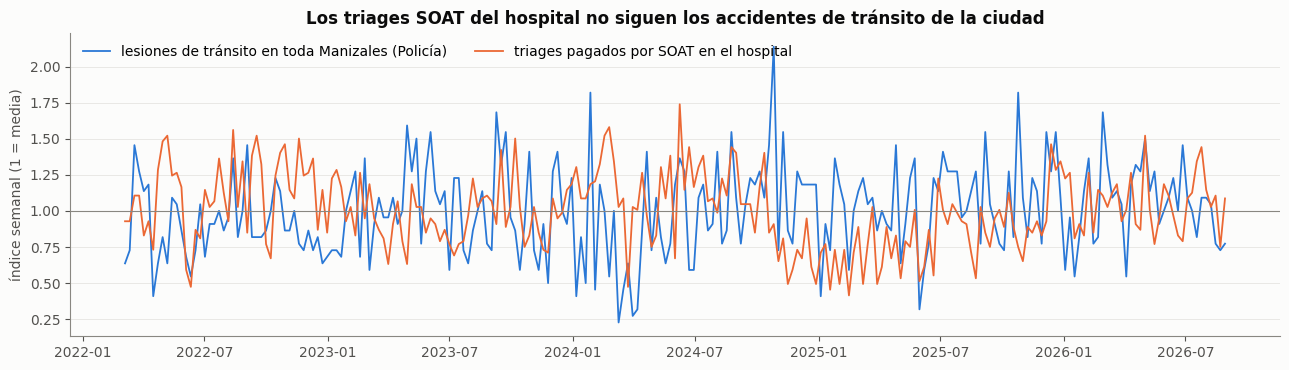

In [12]:
seg = pd.read_csv(RAIZ / "calendarios" / "seguridad_mindefensa.csv.gz", parse_dates=["fecha"]).set_index("fecha")
soat = g["soat_aseguradora"].reindex(pd.date_range("2020-01-01", FIN)).fillna(0)
A = pd.DataFrame({"ciudad": seg["lesiones_transito"], "SOAT en el hospital": soat}).loc["2022-03-01":"2026-08-28"]
Aw = A.resample("W-SAT").sum()
print(f"casos por día, 2022-03 a 2026-08: tránsito en la ciudad {A.ciudad.mean():.1f}, SOAT en el hospital {A['SOAT en el hospital'].mean():.1f}")
print(f"r semanal en conteo: {Aw.ciudad.corr(Aw['SOAT en el hospital']):+.3f}   ({len(Aw)} semanas)")

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(Aw.index, Aw.ciudad / Aw.ciudad.mean(), color=AZUL, lw=1.3, label="lesiones de tránsito en toda Manizales (Policía)")
ax.plot(Aw.index, Aw["SOAT en el hospital"] / Aw["SOAT en el hospital"].mean(), color=NARANJA, lw=1.3, label="triages pagados por SOAT en el hospital")
ax.axhline(1, color=MUDO, lw=.8); ax.set_ylabel("índice semanal (1 = media)"); ax.grid(axis="y")
ax.set_title("Los triages SOAT del hospital no siguen los accidentes de tránsito de la ciudad"); ax.legend(loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

## Lectura

**Los triages SOAT del hospital no se mueven con los accidentes de la ciudad:** la correlación semanal en
conteo sale prácticamente cero (r = −0,005 en 235 semanas) y el cuaderno 07, descontando calendario y año,
da r = +0,01 por día y por semana. El hospital recibe unos 7 triages SOAT por día y la Policía registra
unos 3 lesionados por día en toda Manizales: no son la misma población. Es coherente con que los
accidentados de la ciudad vayan sobre todo a otras clínicas, y que al hospital lleguen remitidos de otros
municipios, accidentes no denunciados o consultas días después. Solo en la Feria de Manizales suben ambos
(cuaderno 07: el SOAT sube +37 % frente a +12 % en otros regresos de vacaciones). Por eso el tránsito de la
ciudad no entra como predictor del triage del hospital y la Feria sí.

**Límites.**
- La clasificación de entidades se hizo por nombre y es un borrador; los grupos pequeños («otro», 0,2 %;
  «ente territorial», 1,3 %) pueden esconder aseguradoras SOAT o ARL mal clasificadas.
- Los triages sin entidad son el 0,99 % en 2025 y el 1,16 % en 2026, y eran cero hasta 2024.
- La serie de la Policía solo cuenta lo denunciado y tiene escalones de registro
  (documentación de fuentes externas).
- La residencia del paciente no se usa.

---
# 6. Mapa de variables

In [13]:
filas = [
    ("conteo total",       "población",   "100 %",     "2020", "sí",           "el desenlace"),
    ("edad en bandas",     "población",   "100 %",     "2020", "sí",           "estacionalidad pediátrica"),
    ("hora de llegada",    "población",   "100 %",     "2020", "sí",           "13,9 veces entre pico y valle"),
    ("entidad admin.",     "red",         "99-100 %",  "2020", "sí",           "Nueva EPS fija el nivel del total"),
    ("nivel de triage",    "institución", "100 %",     "2020", "con reservas", "deriva de criterio desde 2025"),
    ("estancia",           "institución", "91 %",      "2020", "con reservas", "solo el régimen 2 (ago-2021 a jun-2026)"),
    ("motivo (texto)",     "población",   "76-83 %",   "2025", "parcial",      "texto libre, solo desde 2025"),
    ("diagnóstico CIE-10", "población",   "0,6 %",     "-",    "no",           "vacío en el triage; existe para los ingresos"),
]
print(f"{'variable':<20}{'mide':<13}{'cobert.':<10}{'desde':<7}{'usable':<14}{'nota'}")
for f in filas:
    print(f"{f[0]:<20}{f[1]:<13}{f[2]:<10}{f[3]:<7}{f[4]:<14}{f[5]}")

variable            mide         cobert.   desde  usable        nota
conteo total        población    100 %     2020   sí            el desenlace
edad en bandas      población    100 %     2020   sí            estacionalidad pediátrica
hora de llegada     población    100 %     2020   sí            13,9 veces entre pico y valle
entidad admin.      red          99-100 %  2020   sí            Nueva EPS fija el nivel del total
nivel de triage     institución  100 %     2020   con reservas  deriva de criterio desde 2025
estancia            institución  91 %      2020   con reservas  solo el régimen 2 (ago-2021 a jun-2026)
motivo (texto)      población    76-83 %   2025   parcial       texto libre, solo desde 2025
diagnóstico CIE-10  población    0,6 %     -      no            vacío en el triage; existe para los ingresos


---
# Conclusiones

1. **Tres familias de variables, no dos.** El conteo, la edad y la hora describen a la población; el nivel
   y la estancia, al hospital; la entidad administradora, a la red. El conteo total depende sobre todo de la
   red: Nueva EPS es el 58,2 % de los triages y su caída (115,8 a 72,2 por día entre 2025 y 2026) explica
   casi toda la caída del volumen desde 2024.
2. **El 54,4 % de las consultas son de personas de 15 a 44 años**, población en edad laboral. Los extremos de
   edad ganan cuota porque los adultos caen más, no porque lleguen más niños (15-44: 122,1 a 88,1 por día
   de 2024 a 2026; 0-4: 6,8 a 6,9). Si eso se debe a Nueva EPS no puede separarse sin un cruce edad ×
   aseguradora.
3. **La estacionalidad pediátrica es entre 5 y 15 veces la adulta** (amplitud de 72,7 % en 0-4 años y 43,6 %
   en 5-14, contra 5,0 % a 8,2 % en adultos). El pico cae entre marzo y junio en seis de siete años y
   acompaña la IRA pediátrica de la ciudad (r = 0,703 en 312 semanas), pero coincide con la temporada de
   lluvias y con el calendario escolar y los datos no permiten separarlos. El paso de seco a lluvioso tiene
   la forma esperada en 0-4 años (+13,4 ± 15,0 % a 7-13 días), sin distinguirse de cero.
4. **El nivel de triage mide la decisión del hospital, no la gravedad.** Más de la mitad de los triages son
   «no urgente» o «consulta externa», pero el nivel predice si el hospital atiende (93 % de los «IIIU»
   ingresan) o redirige (0,02 % de los «V»). Todos los registros son demanda real.
5. **El criterio del nivel derivó desde enero de 2025**: «no urgente» pasa de 48,4 % a 26,9 % de los
   triages entre 2024 y 2026 y «diferido» de 14,3 % a 37,7 %. De enero a octubre de 2025 el cambio es de
   criterio; desde noviembre coincide con la caída de Nueva EPS. El nivel sirve dentro de un periodo, no
   entre periodos.
6. **La estancia tiene tres regímenes de medición** (10, 56 y 10 minutos de media) y solo es utilizable de
   agosto de 2021 a junio de 2026.
7. **El diagnóstico CIE-10 del triage está vacío** (0,6 %). El diagnóstico estructurado existe solo para los
   ingresos, que son entre el 30 % y el 35 % de los triages desde 2024.
8. **El SOAT del hospital no sigue los accidentes de tránsito de la ciudad** (r = −0,005 semanal); el
   tránsito de la ciudad no sirve como predictor, la Feria sí.

# Límites del análisis

- La composición por edad y por nivel no se puede cruzar con la aseguradora: no se sabe a quién dejó de
  atender el hospital cuando cayó Nueva EPS, ni qué nivel tenía.
- El porcentaje de ingreso por nivel y por edad viene de agregados mensuales con casillas ocultas por debajo
  de 5 casos.
- Las bandas de edad son anchas (15-44 mezcla estudiantes, trabajadores y embarazadas).
- La estacionalidad pediátrica y la de lluvias están confundidas con el calendario escolar y con la
  circulación viral; este cuaderno solo las describe.
- La lluvia solo tiene pluviómetro válido en el 34,7 % de los días: sirve para climatología mensual, no para
  transiciones día a día.
- La clasificación de entidades es por nombre y puede tener errores en los grupos pequeños.
- Las fechas de los cambios de régimen de la estancia se leen de la media diaria, sin acceso a la
  distribución.